# Discriminative Project — Milestone 2: Object Detection (YOLOv8)

We combine existing single object photographs into 2×2 and 3×3 images, generating at least 100 images per student. Background only photographs are excluded.

We trained YOLOv8 to predict object IDs and bounding boxes, then evaluate it on unseen combinations from both layouts.




## 0. Setup

In [1]:
!pip install -q ultralytics

import os, io, json, random, shutil, time
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageEnhance, ImageOps

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Setup complete.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 5.2 MB/s eta 0:00:00
Setup complete.


## 1. CONFIG

This section sets the dataset path, group size, number of generated images, image dimensions, and validation split. We generate at least 100 images per student, include both 2×2 and 3×3 layouts, and exclude background only photographs.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
DATASET_ROOT = '/content/drive/MyDrive/IE7615 Deep Learning for AI'

GROUP_SIZE = 3
MIN_REQUIRED_IMAGES = GROUP_SIZE * 100
N_SYNTHETIC_IMAGES = max(400, MIN_REQUIRED_IMAGES)

OBJECT_COUNT_WEIGHTS = [
    (2, 1), (3, 1),
    (4, 5),   # 2x2 grid layout
    (5, 1), (6, 1), (7, 1), (8, 1),
    (9, 5),   # 3x3 grid layout
]
GRID_LAYOUT_THRESHOLD = 4

CANVAS_SIZE = 640
VAL_FRACTION = 0.15

OUT_DIR = Path('/content/drive/MyDrive/Discriminative_Project/milestone2_outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)

YOLO_DATA_DIR = Path('/content/yolo_dataset')

print(f"Minimum required images ({GROUP_SIZE} students x 100): {MIN_REQUIRED_IMAGES}")
print(f"Generating: {N_SYNTHETIC_IMAGES}")


Mounted at /content/drive
Minimum required images (3 students x 100): 300
Generating: 400


## 2. Copy dataset to local disk



In [3]:
LOCAL_DATASET_ROOT = '/content/dataset_local'

print(f"Copying dataset from Drive to local disk")
t0 = time.time()
!rm -rf "{LOCAL_DATASET_ROOT}"
!mkdir -p "{LOCAL_DATASET_ROOT}"
!cp -r "{DATASET_ROOT}/." "{LOCAL_DATASET_ROOT}/"
print(f"Done in {time.time()-t0:.1f}s")

DATASET_ROOT = LOCAL_DATASET_ROOT


Copying dataset from Drive to local disk
Done in 165.1s


## 3. Build the list of source images per class

This cell groups photographs by object ID, excludes background only and unreadable files, and removes exact duplicates. It then divides the photographs into training, validation, and test sets before generating composites, keeping source images separate across the three sets.


In [4]:
import hashlib

dataset_root = Path(DATASET_ROOT)
class_folders = sorted(
    p for p in dataset_root.iterdir()
    if p.is_dir() and p.name.startswith("images_")
)

class_images = {}
seen_hashes = {}
skipped_files = []

for folder in class_folders:
    obj_id = folder.name.replace("images_", "", 1)
    files = []

    for path in sorted(folder.glob("*")):
        if path.suffix.lower() not in (".jpg", ".jpeg", ".png"):
            continue
        if "_bg_" in path.stem.lower():
            continue

        try:
            with Image.open(path) as image:
                image.verify()
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
        except Exception as error:
            skipped_files.append((str(path), str(error)))
            continue

        if digest in seen_hashes:
            previous_id = seen_hashes[digest]
            if previous_id != obj_id:
                raise ValueError(
                    f"Identical photograph assigned to different IDs: "
                    f"{previous_id} and {obj_id}. Resolve before training."
                )
            continue

        seen_hashes[digest] = obj_id
        files.append(path)

    if files:
        class_images[obj_id] = files

class_names = sorted(class_images)
class_to_index = {name: i for i, name in enumerate(class_names)}
index_to_class = {i: name for name, i in class_to_index.items()}

TEST_FRACTION = 0.15
split_rng = random.Random(SEED)
source_pools = {split: {} for split in ("train", "val", "test")}

for obj_id, files in class_images.items():
    files = list(files)
    split_rng.shuffle(files)

    if len(files) < 7:
        raise ValueError(f"{obj_id} needs at least 7 unique source photographs.")

    n_val_sources = max(1, int(len(files) * VAL_FRACTION))
    n_test_sources = max(1, int(len(files) * TEST_FRACTION))

    source_pools["val"][obj_id] = files[:n_val_sources]
    source_pools["test"][obj_id] = files[
        n_val_sources:n_val_sources + n_test_sources
    ]
    source_pools["train"][obj_id] = files[
        n_val_sources + n_test_sources:
    ]

print(f"Classes: {len(class_names)}")
print(f"Unique usable source photographs: {sum(map(len, class_images.values()))}")
print(f"Unreadable files skipped: {len(skipped_files)}")
print("Background only photographs excluded.")
print("Source photographs are separated before generating composites.")

Classes: 73
Unique usable source photographs: 6948
Unreadable files skipped: 0
Background only photographs excluded.
Source photographs are separated before generating composites.


## 4. Generate the synthetic multi object dataset

This section combines randomly selected single object photographs into 2×2 and 3×3 grids. Training images receive random horizontal flips and brightness and contrast adjustments. Each composite is saved with a matching YOLO label file containing class IDs and normalized bounding box coordinates, using photograph tile boundaries unless actual object annotations are provided.

Images and labels are written directly into the YOLO directory layout Ultralytics expects.


In [5]:
SOURCE_BOXES_FILE = OUT_DIR / "source_object_boxes.json"
source_object_boxes = (
    json.loads(SOURCE_BOXES_FILE.read_text())
    if SOURCE_BOXES_FILE.exists() else None
)

BOX_LABEL_MODE = (
    "actual_object_boxes"
    if source_object_boxes is not None
    else "photo_tile_boxes"
)

if source_object_boxes is not None:
    for obj_id, paths in class_images.items():
        for path in paths:
            key = path.relative_to(dataset_root).as_posix()
            if key not in source_object_boxes:
                raise ValueError(f"Missing source object annotation: {key}")

            with Image.open(path) as image:
                width, height = image.size

            x1, y1, x2, y2 = source_object_boxes[key]
            if not (0 <= x1 < x2 <= width and 0 <= y1 < y2 <= height):
                raise ValueError(f"Invalid source bounding box: {key}")
else:
    print(
        "WARNING: No source object annotations found. "
        "Labels and evaluation will describe photograph tiles, "
    )

def iou(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b
    intersection = (
        max(0, min(ax2, bx2) - max(ax1, bx1))
        * max(0, min(ay2, by2) - max(ay1, by1))
    )
    union = (
        (ax2 - ax1) * (ay2 - ay1)
        + (bx2 - bx1) * (by2 - by1)
        - intersection
    )
    return intersection / union if union > 0 else 0.0

def generate_one_image(
    canvas_size, weights=None, grid_threshold=None,
    split="train", grid_n=None, augment=None
):
    if grid_n is None:
        grid_n = random.choice((2, 3))
    if augment is None:
        augment = split == "train"

    edges = [
        round(i * canvas_size / grid_n)
        for i in range(grid_n + 1)
    ]
    canvas = Image.new("RGB", (canvas_size, canvas_size))
    labels, source_paths = [], []

    selected_ids = random.sample(class_names, grid_n * grid_n)

    for position, obj_id in enumerate(selected_ids):
        row, column = divmod(position, grid_n)
        left, top = edges[column], edges[row]
        right, bottom = edges[column + 1], edges[row + 1]
        tile_width, tile_height = right - left, bottom - top

        path = random.choice(source_pools[split][obj_id])
        with Image.open(path) as image:
            patch = image.convert("RGB")

        width, height = patch.size
        key = path.relative_to(dataset_root).as_posix()

        if source_object_boxes is None:
            x1, y1, x2, y2 = 0, 0, width, height
        else:
            x1, y1, x2, y2 = source_object_boxes[key]

        if augment:
            if random.random() < 0.5:
                patch = ImageOps.mirror(patch)
                x1, x2 = width - x2, width - x1

            patch = ImageEnhance.Brightness(patch).enhance(
                random.uniform(0.85, 1.15)
            )
            patch = ImageEnhance.Contrast(patch).enhance(
                random.uniform(0.85, 1.15)
            )

        patch = patch.resize(
            (tile_width, tile_height),
            Image.Resampling.BICUBIC
        )
        canvas.paste(patch, (left, top))

        labels.append((
            obj_id,
            left + x1 * tile_width / width,
            top + y1 * tile_height / height,
            left + x2 * tile_width / width,
            top + y2 * tile_height / height
        ))
        source_paths.append(key)

    return canvas, labels, source_paths

def boxes_to_yolo_lines(labels, class_to_index, canvas_size):
    lines = []
    for obj_id, x1, y1, x2, y2 in labels:
        assert 0 <= x1 < x2 <= canvas_size
        assert 0 <= y1 < y2 <= canvas_size

        lines.append(
            f"{class_to_index[obj_id]} "
            f"{(x1 + x2) / (2 * canvas_size):.8f} "
            f"{(y1 + y2) / (2 * canvas_size):.8f} "
            f"{(x2 - x1) / canvas_size:.8f} "
            f"{(y2 - y1) / canvas_size:.8f}"
        )
    return lines

print("2×2 and 3×3 generation functions ready.")
print(f"Bounding box label mode: {BOX_LABEL_MODE}")

2×2 and 3×3 generation functions ready.
Bounding box label mode: photo_tile_boxes


In [6]:
import yaml

YOLO_DATA_DIR = Path("/content/yolo_dataset_gapfree")
YOLO_DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

images_per_student = max(
    100, (N_SYNTHETIC_IMAGES + GROUP_SIZE - 1) // GROUP_SIZE
)
images_per_student += images_per_student % 2
N_SYNTHETIC_IMAGES = GROUP_SIZE * images_per_student

manifest = []
used_combinations = set()
t0 = time.time()

for split in ("train", "val", "test"):
    (YOLO_DATA_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DATA_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

for student in range(1, GROUP_SIZE + 1):
    for grid_n in (2, 3):
        layout_count = images_per_student // 2
        n_val = max(1, round(layout_count * VAL_FRACTION))
        n_test = max(1, round(layout_count * TEST_FRACTION))
        counts = {
            "train": layout_count - n_val - n_test,
            "val": n_val,
            "test": n_test
        }

        for split, count in counts.items():
            for number in range(count):
                for attempt in range(1000):
                    canvas, labels, sources = generate_one_image(
                        CANVAS_SIZE, split=split, grid_n=grid_n
                    )
                    signature = tuple(sorted(sources))
                    if signature not in used_combinations:
                        used_combinations.add(signature)
                        break
                else:
                    raise RuntimeError("Could not generate a new source combination.")

                stem = (
                    f"student{student}_{grid_n}x{grid_n}_"
                    f"{split}_{number:04d}"
                )
                canvas.save(
                    YOLO_DATA_DIR / "images" / split / f"{stem}.jpg",
                    quality=95
                )
                (YOLO_DATA_DIR / "labels" / split / f"{stem}.txt").write_text(
                    "\n".join(
                        boxes_to_yolo_lines(
                            labels, class_to_index, CANVAS_SIZE
                        )
                    ) + "\n"
                )
                manifest.append({
                    "image": f"{stem}.jpg",
                    "student": student,
                    "split": split,
                    "layout": f"{grid_n}x{grid_n}",
                    "sources": sources
                })

manifest_df = pd.DataFrame(manifest)

data_config = {
    "path": str(YOLO_DATA_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": dict(enumerate(class_names))
}
(YOLO_DATA_DIR / "data.yaml").write_text(
    yaml.safe_dump(data_config, sort_keys=False)
)
shutil.copy(YOLO_DATA_DIR / "data.yaml", OUT_DIR / "data.yaml")

(OUT_DIR / "class_names.json").write_text(
    json.dumps(class_names, indent=2)
)
(OUT_DIR / "gapfree_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

print(f"Generated {len(manifest)} images in {time.time() - t0:.1f}s.")
print(f"Each student contributed {images_per_student} images.")
print(f"Annotation mode: {BOX_LABEL_MODE}")
display(pd.crosstab(
    [manifest_df["student"], manifest_df["split"]],
    manifest_df["layout"]
))

Generated 402 images in 11.9s.
Each student contributed 134 images.
Annotation mode: photo_tile_boxes


layout         2x2  3x3
student split          
1       test    10   10
        train   47   47
        val     10   10
2       test    10   10
        train   47   47
        val     10   10
3       test    10   10
        train   47   47
        val     10   10

## 4b. Generate clean 2x2 and 3x3 samples for testing

This cell selects one held out test image from each layout, saves it with its matching label file, and displays the clean 2×2 and 3×3 samples without prediction boxes.


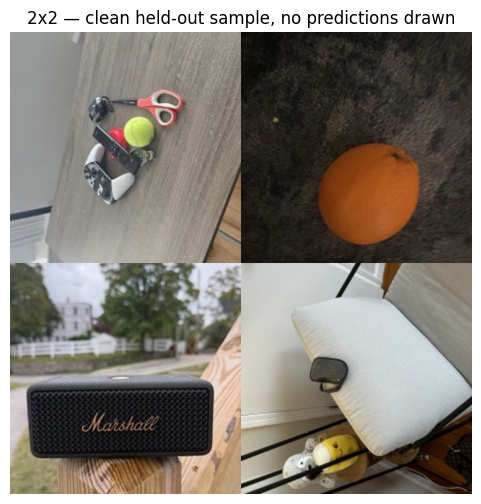

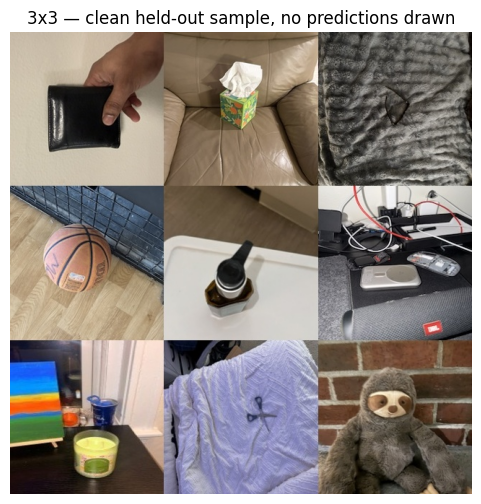

Saved clean 2×2 and 3×3 samples.


In [7]:
samples_dir = OUT_DIR / "ta_samples"
samples_dir.mkdir(parents=True, exist_ok=True)

for layout in ("2x2", "3x3"):
    row = manifest_df[
        (manifest_df["split"] == "test")
        & (manifest_df["layout"] == layout)
    ].iloc[0]

    image_path = YOLO_DATA_DIR / "images/test" / row["image"]
    label_path = (
        YOLO_DATA_DIR / "labels/test" / f"{image_path.stem}.txt"
    )

    shutil.copy(image_path, samples_dir / f"sample_{layout}.jpg")
    shutil.copy(label_path, samples_dir / f"sample_{layout}.txt")

    with Image.open(image_path) as image:
        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.title(f"{layout} — clean held-out sample, no predictions drawn")
        plt.axis("off")
        plt.show()

print("Saved clean 2×2 and 3×3 samples.")

## 5. Sanity check a few generated images

Draw the recorded bounding boxes back onto a few synthetic training images, to confirm the
labels actually line up with where objects were pasted before spending time training on them.


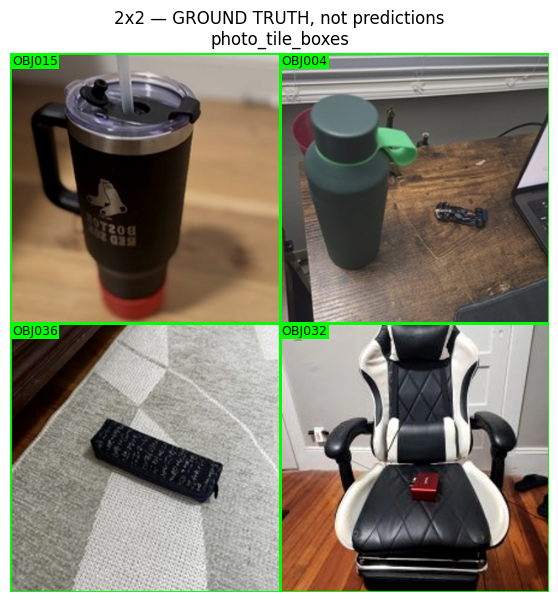

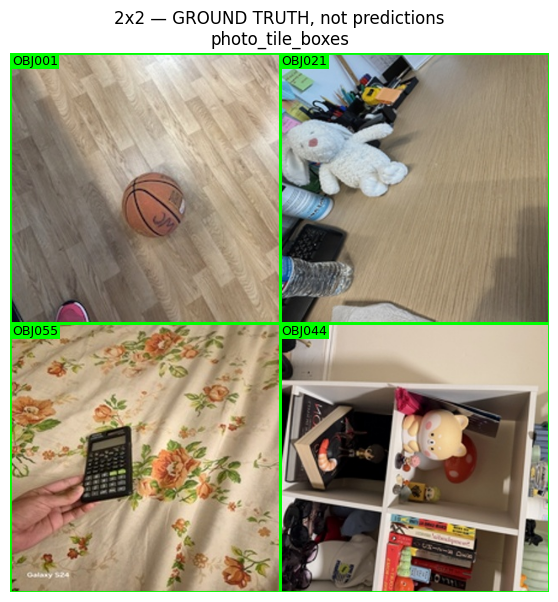

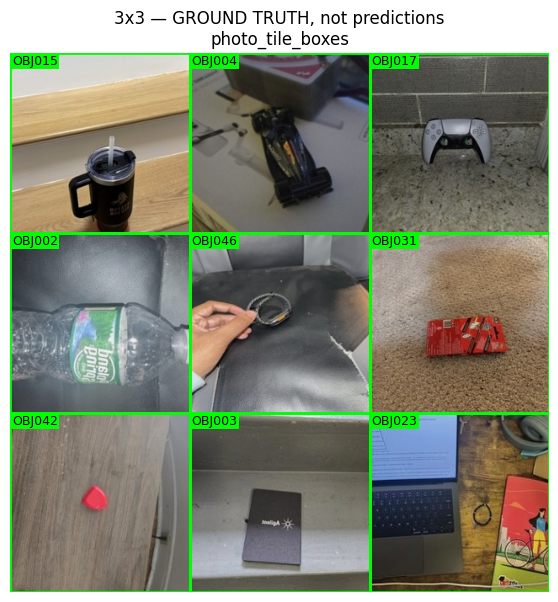

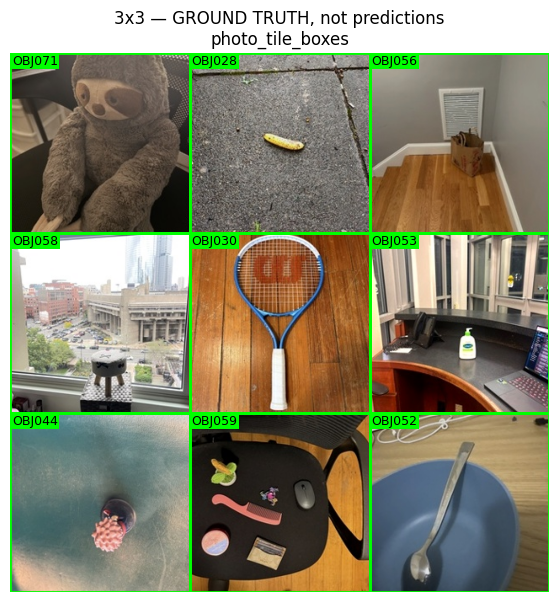

In [8]:
def read_ground_truth(img_path, label_path):
    with Image.open(img_path) as image:
        width, height = image.size

    objects = []
    for line in label_path.read_text().splitlines():
        cls_idx, xc, yc, w, h = map(float, line.split())
        cls_idx = int(cls_idx)
        assert 0 <= cls_idx < len(class_names)

        box = (
            (xc - w / 2) * width,
            (yc - h / 2) * height,
            (xc + w / 2) * width,
            (yc + h / 2) * height
        )
        objects.append((cls_idx, box))

    return objects

def show_sample_with_boxes(img_path, label_path, class_names, title=None):
    with Image.open(img_path) as image:
        image = image.convert("RGB")

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(image)

    for cls_idx, (x1, y1, x2, y2) in read_ground_truth(
        img_path, label_path
    ):
        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="lime", facecolor="none"
        ))
        ax.text(
            x1 + 2, y1 + 2, class_names[cls_idx],
            va="top", color="black", fontsize=9,
            bbox={"facecolor": "lime", "edgecolor": "none", "pad": 1}
        )

    ax.set_title(title or f"GROUND TRUTH — {BOX_LABEL_MODE}")
    ax.axis("off")
    plt.show()

for layout in ("2x2", "3x3"):
    rows = manifest_df[
        (manifest_df["split"] == "train")
        & (manifest_df["layout"] == layout)
    ].head(2)

    for filename in rows["image"]:
        image_path = YOLO_DATA_DIR / "images/train" / filename
        label_path = (
            YOLO_DATA_DIR / "labels/train" / f"{image_path.stem}.txt"
        )
        show_sample_with_boxes(
            image_path, label_path, class_names,
            title=f"{layout} — GROUND TRUTH, not predictions\n{BOX_LABEL_MODE}"
        )

## 6. Train YOLOv8

This cell fine tunes the YOLOv8n model on the generated dataset for up to 50 epochs with a batch size of 16.After training, it loads the best checkpoint for evaluation and checks that the model's class names match the dataset.


In [10]:
from ultralytics import YOLO

EPOCHS = 50
IMG_SIZE = CANVAS_SIZE
BATCH_SIZE = 16

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(YOLO_DATA_DIR / "data.yaml"),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    project=str(OUT_DIR / "runs"),
    name="yolov8_gapfree",
    exist_ok=False,
    mosaic=0.0,
    mixup=0.0
)

best_weights = Path(model.trainer.save_dir) / "weights/best.pt"
detector = YOLO(str(best_weights))

assert [
    detector.names[i] for i in range(len(class_names))
] == class_names

Ultralytics 8.4.175  Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_gapfree/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8_gapfree-2, nbs=64, nms=None, opset=None, opt

## 7. Evaluate on the validation set

This cell evaluates the model separately on held out 2×2 and 3×3 images, reporting mAP, precision, recall, matched object rate, and exact image accuracy. Predictions count as correct when the class ID matches and IoU is at least 0.50, using a confidence threshold of 0.25.

In [11]:
CONF_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50

def score_prediction(prediction, ground_truth):
    predicted = [
        (int(cls), float(conf), box.tolist())
        for cls, conf, box in zip(
            prediction.boxes.cls.cpu().numpy(),
            prediction.boxes.conf.cpu().numpy(),
            prediction.boxes.xyxy.cpu().numpy()
        )
    ]
    predicted.sort(key=lambda item: item[1], reverse=True)

    matched = set()
    tp = 0

    for pred_cls, confidence, pred_box in predicted:
        candidates = [
            (iou(pred_box, gt_box), index)
            for index, (gt_cls, gt_box) in enumerate(ground_truth)
            if index not in matched and pred_cls == gt_cls
        ]
        if candidates:
            overlap, index = max(candidates)
            if overlap >= MATCH_IOU_THRESHOLD:
                matched.add(index)
                tp += 1

    fp = len(predicted) - tp
    fn = len(ground_truth) - tp
    exact = int(fp == 0 and fn == 0)
    return tp, fp, fn, exact

evaluation_rows = []
per_image_rows = []
prediction_cache = {}

for layout in ("2x2", "3x3"):
    filenames = manifest_df[
        (manifest_df["split"] == "test")
        & (manifest_df["layout"] == layout)
    ]["image"].tolist()

    image_paths = [
        YOLO_DATA_DIR / "images/test" / filename
        for filename in filenames
    ]

    image_list = YOLO_DATA_DIR / f"test_{layout}.txt"
    image_list.write_text(
        "\n".join(str(path.resolve()) for path in image_paths) + "\n"
    )

    layout_config = dict(data_config)
    layout_config["test"] = str(image_list)
    layout_yaml = YOLO_DATA_DIR / f"data_{layout}.yaml"
    layout_yaml.write_text(
        yaml.safe_dump(layout_config, sort_keys=False)
    )

    metrics = detector.val(
        data=str(layout_yaml),
        split="test",
        imgsz=IMG_SIZE,
        conf=0.001,
        project=str(OUT_DIR / "layout_evaluation"),
        name=f"test_{layout}",
        plots=True
    )

    totals = np.zeros(4, dtype=int)

    for image_path in image_paths:
        prediction = detector.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=CONF_THRESHOLD,
            verbose=False
        )[0]
        ground_truth = read_ground_truth(
            image_path,
            YOLO_DATA_DIR / "labels/test" / f"{image_path.stem}.txt"
        )

        tp, fp, fn, exact = score_prediction(prediction, ground_truth)
        totals += [tp, fp, fn, exact]
        prediction_cache[image_path.name] = prediction

        per_image_rows.append({
            "image": image_path.name,
            "layout": layout,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "matched_object_rate_pct": 100 * tp / len(ground_truth),
            "exact_image_correct": exact
        })

    tp, fp, fn, exact = map(int, totals)
    evaluation_rows.append({
        "layout": layout,
        "annotation_mode": BOX_LABEL_MODE,
        "test_images": len(image_paths),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
        "precision_maxF1": float(metrics.box.mp),
        "recall_maxF1": float(metrics.box.mr),
        "precision_conf025": tp / max(1, tp + fp),
        "matched_object_rate_pct": 100 * tp / max(1, tp + fn),
        "exact_image_accuracy_pct": 100 * exact / len(image_paths),
        "TP": tp,
        "FP": fp,
        "FN": fn
    })

evaluation_df = pd.DataFrame(evaluation_rows)
per_image_df = pd.DataFrame(per_image_rows)

evaluation_df.to_csv(OUT_DIR / "layout_test_metrics.csv", index=False)
per_image_df.to_csv(OUT_DIR / "per_image_test_metrics.csv", index=False)

eval_summary = {
    "annotation_mode": BOX_LABEL_MODE,
    "confidence_threshold": CONF_THRESHOLD,
    "matching_IoU_threshold": MATCH_IOU_THRESHOLD,
    "layouts": evaluation_rows
}
(OUT_DIR / "eval_summary.json").write_text(
    json.dumps(eval_summary, indent=2)
)

display(evaluation_df.round(4))
print("Test composites use held out source photographs and different combinations.")
if BOX_LABEL_MODE == "photo_tile_boxes":
    print("photograph tile detection results.")

Ultralytics 8.4.175  Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,150,203 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2014.1±526.3 MB/s, size: 124.1 KB)
val: Scanning /content/yolo_dataset_gapfree/labels/test... 30 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 30/30 1.3Kit/s 0.0s
val: New cache created: /content/yolo_dataset_gapfree/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1it/s 1.8s
                   all         30        120      0.696      0.735      0.806      0.805
                OBJ001          2          2      0.957          1      0.995      0.995
                OBJ002          4          4      0.822          1      0.995      0.995
                OBJ003          3          3      0.716      0.667       0.69       0.69
                OBJ005          3          3        0.8          1

,layout,annotation_mode,test_images,mAP50,mAP50_95,precision_maxF1,recall_maxF1,precision_conf025,matched_object_rate_pct,exact_image_accuracy_pct,TP,FP,FN
0,2x2,photo_tile_boxes,30,0.8060,0.8050,0.6963,0.7349,0.8447,72.5000,30.0000,87,16,33
1,3x3,photo_tile_boxes,30,0.7797,0.7775,0.8558,0.6884,0.8362,71.8519,3.3333,194,38,76


Test composites use held out source photographs and different combinations.
photograph tile detection results.


## 8. Run inference on sample images and visualize

Selects a few test images from both 2×2 and 3×3 layouts and displays the model’s predicted object IDs and bounding boxes. These images serve as the sample detection results for the report.



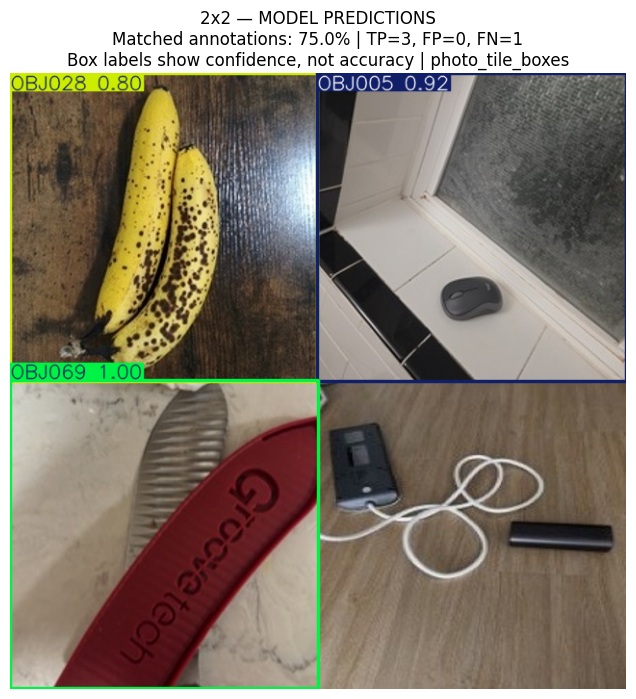

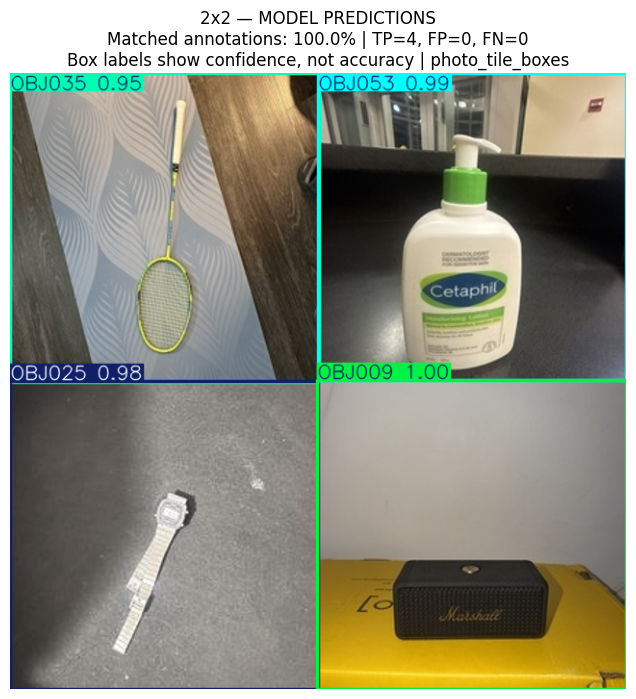

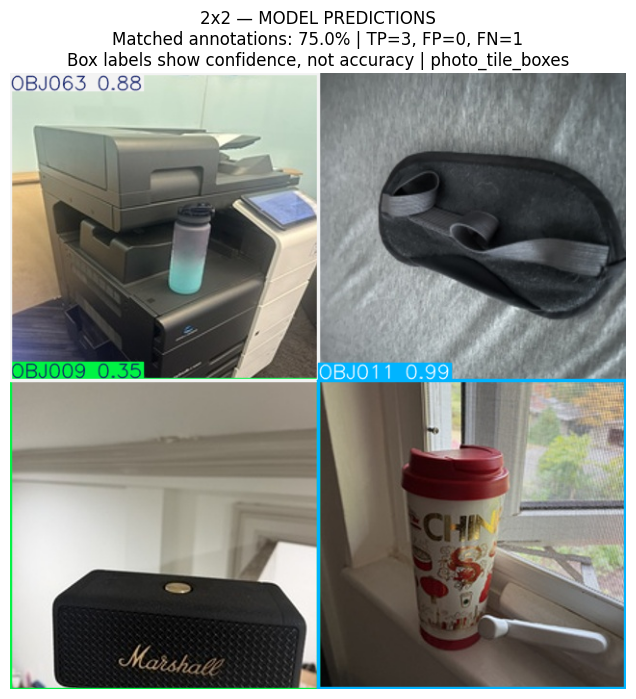

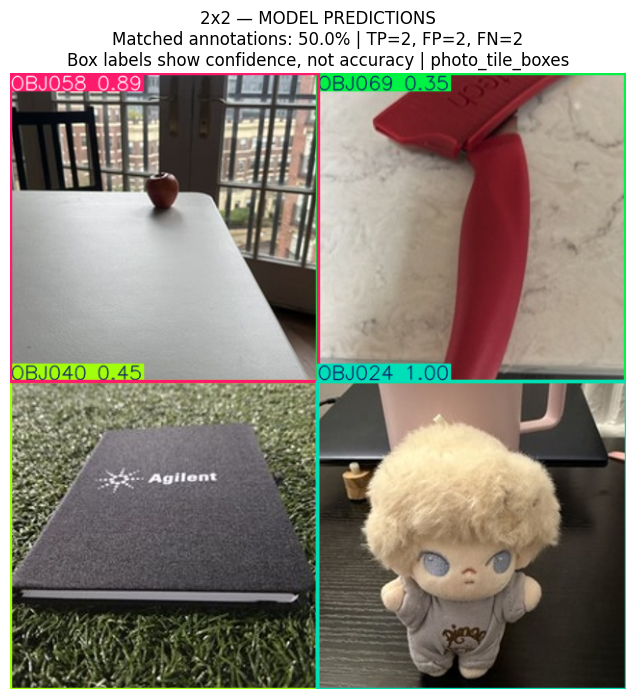

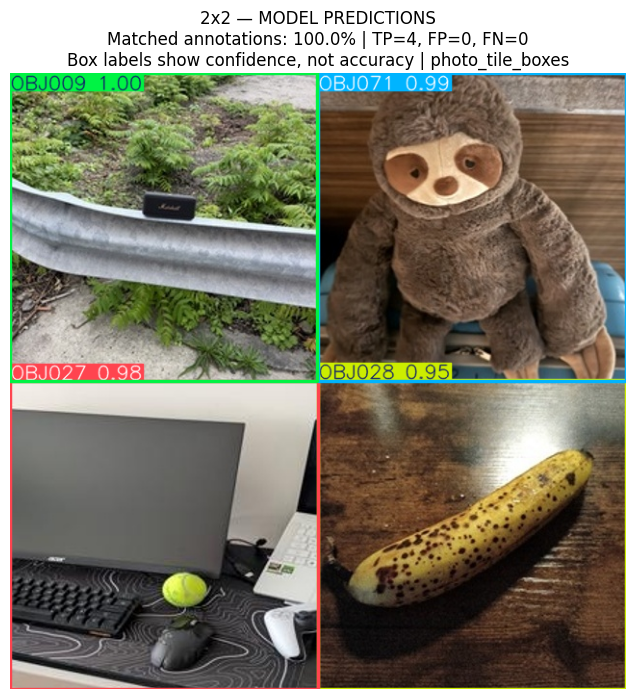

...

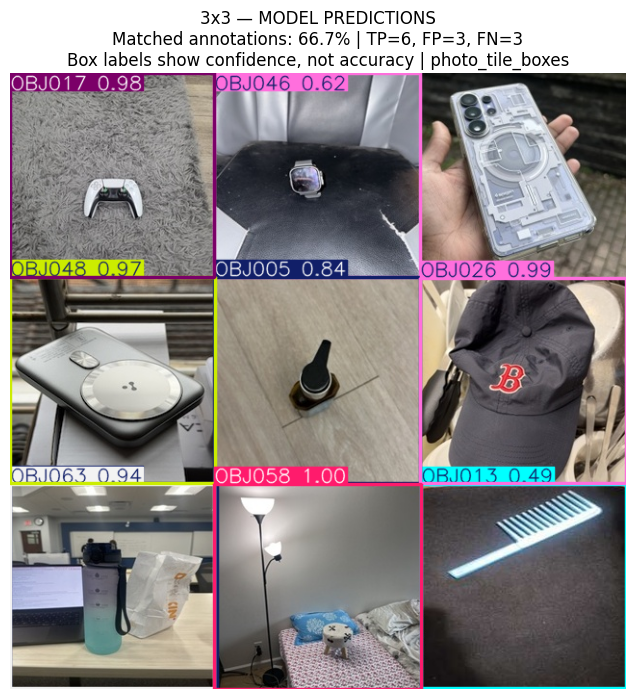

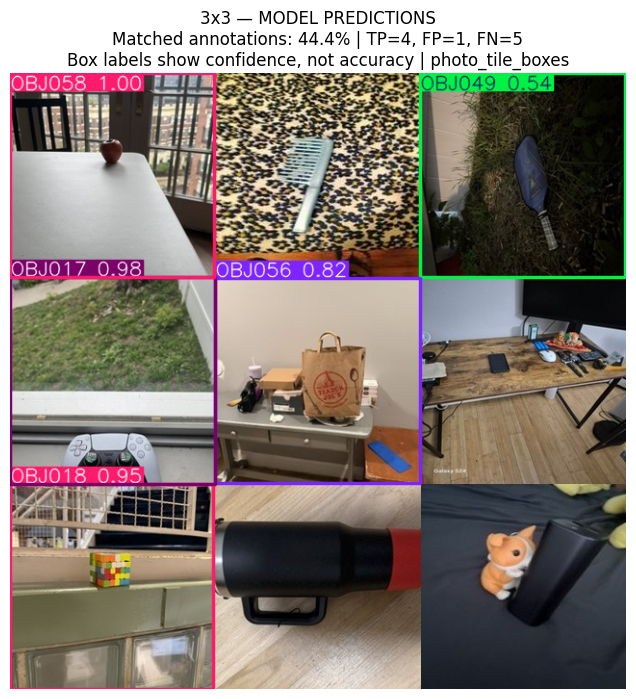

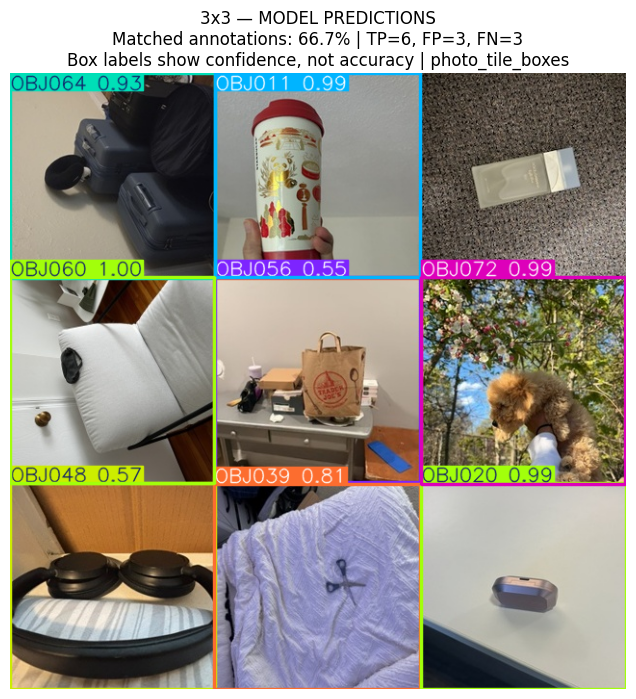

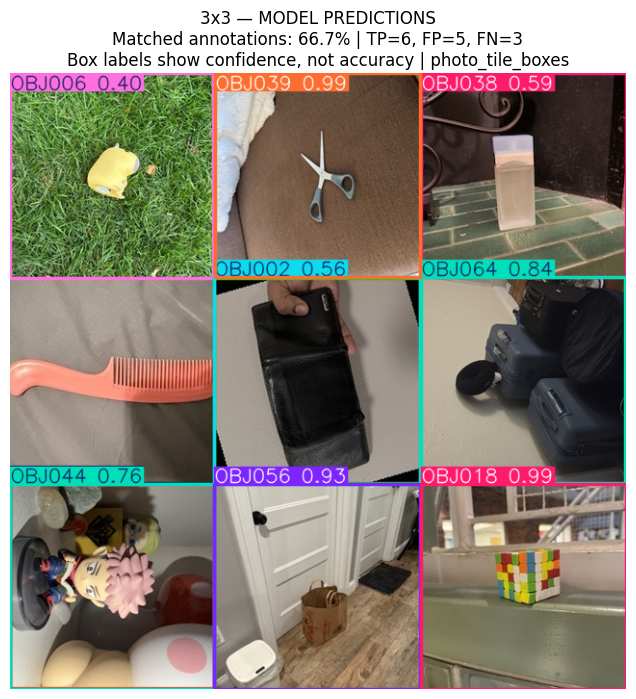

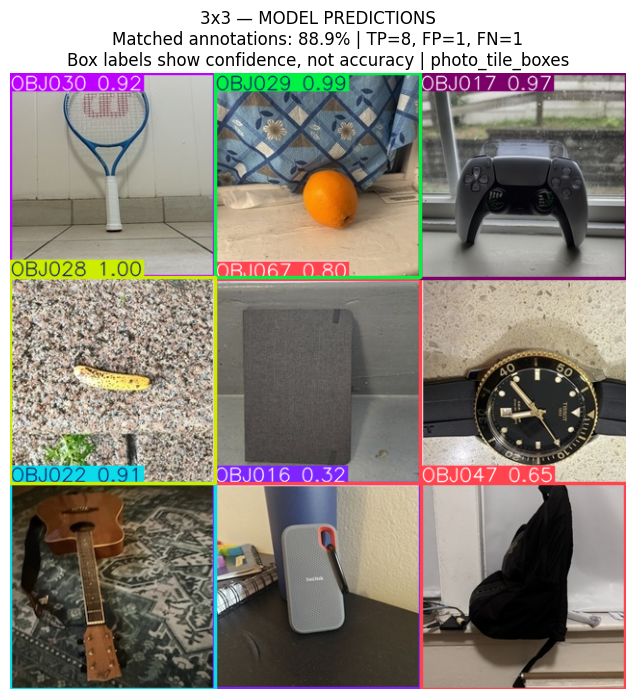

Saved predictions for different held out combinations of both layouts.


In [12]:
inference_out_dir = OUT_DIR / "sample_detections_gapfree"
inference_out_dir.mkdir(parents=True, exist_ok=True)

predicted_locations = []

for layout in ("2x2", "3x3"):
    candidates = per_image_df[per_image_df["layout"] == layout]
    selected = candidates.sample(
        n=min(6, len(candidates)),
        random_state=SEED
    )

    for _, row in selected.iterrows():
        image_path = YOLO_DATA_DIR / "images/test" / row["image"]
        prediction = prediction_cache[image_path.name]

        annotated_rgb = prediction.plot(
            labels=True, conf=True, line_width=2
        )[:, :, ::-1]

        Image.fromarray(annotated_rgb).save(
            inference_out_dir / f"predicted_{image_path.name}"
        )

        for cls, confidence, box in zip(
            prediction.boxes.cls.cpu().numpy(),
            prediction.boxes.conf.cpu().numpy(),
            prediction.boxes.xyxy.cpu().numpy()
        ):
            predicted_locations.append({
                "image": image_path.name,
                "layout": layout,
                "object_id": detector.names[int(cls)],
                "confidence": float(confidence),
                "x_min": float(box[0]),
                "y_min": float(box[1]),
                "x_max": float(box[2]),
                "y_max": float(box[3])
            })

        plt.figure(figsize=(8, 8))
        plt.imshow(annotated_rgb)
        plt.title(
            f"{layout} — MODEL PREDICTIONS\n"
            f"Matched annotations: {row['matched_object_rate_pct']:.1f}% | "
            f"TP={row['TP']}, FP={row['FP']}, FN={row['FN']}\n"
            f"Box labels show confidence, not accuracy | {BOX_LABEL_MODE}"
        )
        plt.axis("off")
        plt.show()

pd.DataFrame(
    predicted_locations,
    columns=[
        "image", "layout", "object_id", "confidence",
        "x_min", "y_min", "x_max", "y_max"
    ]
).to_csv(OUT_DIR / "predicted_ids_locations.csv", index=False)

print("Saved predictions for different held out combinations of both layouts.")

## 9. Save the trained model

In [13]:
best_weights = Path(model.trainer.save_dir) / "weights" / "best.pt"

if best_weights.exists():
    shutil.copy(best_weights, OUT_DIR / "yolov8_best.pt")
    print("Best model saved.")
else:
    print("Best model weights not found.")

Best model saved.
